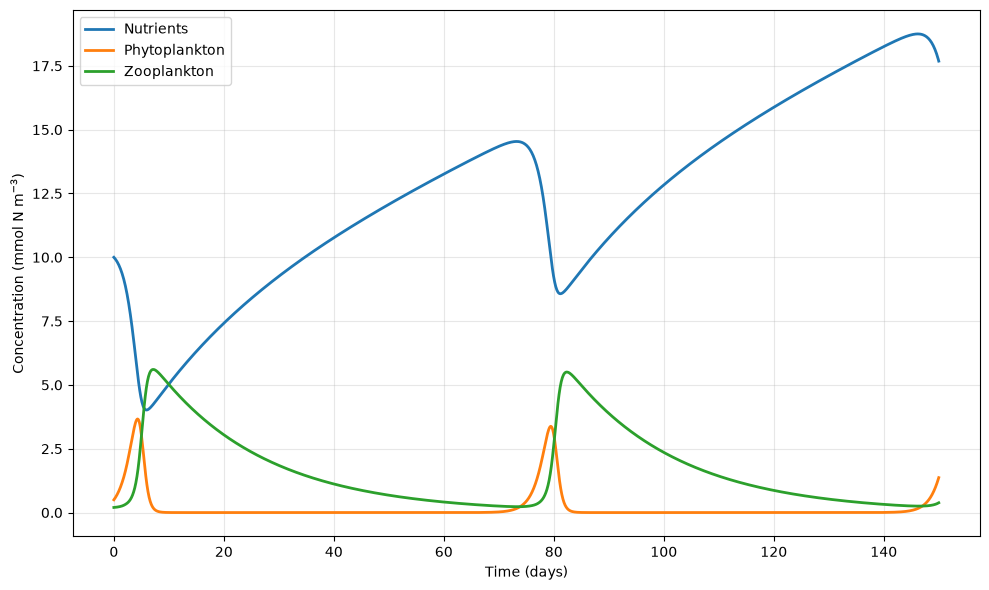

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp


# ============================================================
# SIMPLE NPZ MODEL - TEXTBOOK VERSION
# ============================================================
#
# N = nutrients (DIN + DON)
# P = phytoplankton
# Z = zooplankton
#
# All concentrations in mmol N m^-3
# Time in days
#
# Includes:
# - Constant nutrient supply
# - Light-dependent phytoplankton growth
# - Nutrient limitation
# - Zooplankton grazing
# - Mortality
# - Remineralization
# - Export


# ============================================================
# MODEL PARAMETERS
# ============================================================

# Nutrient supply
F0 = 0.1          # mmol N m^-3 day^-1

# Phytoplankton growth
Vmax = 1.0         # maximum growth rate (day^-1)
K_N = 0.5          # nutrient half-saturation (mmol N m^-3)

# Light limitation (0 to 1)
light_lim = 0.8

# Phytoplankton mortality
lambda_P = 0.1     # mortality rate (day^-1)

# Fraction of phytoplankton mortality remineralized
mu_P = 0.7

# Zooplankton grazing
g = 0.4            # grazing coefficient
K_P = 1.0          # grazing scaling parameter (mmol N m^-3)

# Zooplankton assimilation efficiency
gamma_Z = 0.7

# Zooplankton mortality
lambda_Z = 0.05    # mortality rate (day^-1)

# Fraction of zooplankton losses remineralized
mu_Z = 0.7


# ============================================================
# NPZ MODEL EQUATIONS
# ============================================================

def npz_model(t, y):

    N, P, Z = y

    # ----------------------------------------
    # Phytoplankton growth
    # ----------------------------------------

    nutrient_lim = N / (K_N + N)

    growth = Vmax * light_lim * nutrient_lim * P

    # ----------------------------------------
    # Zooplankton grazing
    # ----------------------------------------

    grazing = g * Z * P / K_P

    # ----------------------------------------
    # Mortality
    # ----------------------------------------

    phyto_mortality = lambda_P * P
    zoo_mortality = lambda_Z * Z

    # ----------------------------------------
    # Remineralization
    # ----------------------------------------

    phyto_remin = mu_P * phyto_mortality

    zoo_remin = mu_Z * (
        (1 - gamma_Z) * grazing
        + zoo_mortality
    )

    # ----------------------------------------
    # Export
    # ----------------------------------------

    phyto_export = (1 - mu_P) * phyto_mortality

    zoo_export = (1 - mu_Z) * (
        (1 - gamma_Z) * grazing
        + zoo_mortality
    )

    # ----------------------------------------
    # Differential equations
    # ----------------------------------------

    dNdt = (
        F0
        - growth
        + phyto_remin
        + zoo_remin
    )

    dPdt = (
        growth
        - grazing
        - phyto_mortality
    )

    dZdt = (
        gamma_Z * grazing
        - zoo_mortality
    )

    return [dNdt, dPdt, dZdt]


# ============================================================
# INITIAL CONDITIONS
# ============================================================

N0 = 10.0
P0 = 0.5
Z0 = 0.2

initial_conditions = [N0, P0, Z0]


# ============================================================
# TIME
# ============================================================

t = np.linspace(0, 150, 1500)


# ============================================================
# RUN MODEL
# ============================================================

solution = solve_ivp(
    npz_model,
    [t[0], t[-1]],
    initial_conditions,
    t_eval=t
)

N = solution.y[0]
P = solution.y[1]
Z = solution.y[2]


# ============================================================
# PLOT
# ============================================================

fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(t, N, label="Nutrients", linewidth=2)
ax.plot(t, P, label="Phytoplankton", linewidth=2)
ax.plot(t, Z, label="Zooplankton", linewidth=2)

ax.set_xlabel("Time (days)")
ax.set_ylabel("Concentration (mmol N m$^{-3}$)")

ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()